# Занятие 4, пара 2. Бинаризация, морфология и контуры

Автор ноутбука - Дуркин Анатолий Альбертович

Старший преподаватель кафедры прикладной математики и компьютерных наук СГУ им. Питирима Сорокина

Замечания, предложения, идеи, вопросы, связь с автором:
- anatoliy.durkin@mail.ru
- Telegram - @AnatoDu

Больше информации и материалов на канале автора: https://t.me/code_matan_ai

**Как проходить тетрадь.** Основные примеры работают независимо от заданий «Ваш ход». Если пока пропускаете задание, пропустите и его ячейку `check(...)`; продолжайте со следующего обычного раздела. Упражнения могут использовать ответы предыдущих упражнений. Сохраните свои попытки в отдельной копии тетради.

## От яркости к маске и размеру предмета

Край — линия перехода. Маска отвечает на другой вопрос: какие пиксели относим к объекту? На этой паре построим простую маску по порогу, посмотрим, как минимум и максимум соседей меняют её, и измерим ширину учебного предмета по эталону.

Основной маршрут — **NumPy и Matplotlib**, без OpenCV, сети и камеры. Используем маленькие массивы и синтетический снимок с известными размерами. Измерение по такой картинке помогает разобраться с единицами, но ещё не доказывает точность на реальной фотографии с перспективой.

Результат: три упражнения, опыты с эрозией/дилатацией и расчёт погрешности. Основные объяснения находятся здесь; для самостоятельного чтения преподавательская копия не нужна.


### Подключим учебные файлы

Следующая ячейка — служебная настройка комплекта. Она находит папку `course_support` у текущей папки или выше и подключает данные и проверки. Её не нужно писать по памяти или менять для задания. `DATA_DIR` — путь к учебным данным, `WORKSPACE_DIR` — корень вашей рабочей папки. `check(номер, ответы)` сравнивает ответ с условиями упражнения, но не выставляет оценку.

Работайте в своей копии и запускайте ячейки сверху вниз. Переменные из другой тетради не нужны. Если поддержку не удалось найти, откройте тетрадь внутри полного комплекта, а не переносите один файл отдельно. Git и интернет для основной работы не нужны.


In [ ]:
import sys
from pathlib import Path

# Одинаковый запуск в репозитории курса и в личном проекте.
for WORKSPACE_DIR in (Path.cwd(), *Path.cwd().parents):
    if (WORKSPACE_DIR / 'course_support' / '__init__.py').is_file():
        break
else:
    raise FileNotFoundError('Откройте тетрадь внутри папки с course_support; нужен весь комплект проекта')

# При переключении курса в том же kernel не оставляем чужую поддержку в памяти.
loaded = sys.modules.get('course_support')
expected = WORKSPACE_DIR / 'course_support' / '__init__.py'
if loaded is not None and Path(loaded.__file__).resolve() != expected.resolve():
    for name in list(sys.modules):
        if name == 'course_support' or name.startswith('course_support.'):
            del sys.modules[name]
sys.path.insert(0, str(WORKSPACE_DIR))
from course_support import SUPPORT_DIR, DATA_DIR
COURSE_DIR = SUPPORT_DIR
# Только упражнения о личном README: в репозитории курса это ещё чистый шаблон.
PROJECT_DIR = WORKSPACE_DIR / 'project_template' if (WORKSPACE_DIR / 'project_template').is_dir() else WORKSPACE_DIR
from course_support.checks import check, summary

PROJECT_DIR


### Подключим только то, что понадобится для самостоятельной работы

`numpy` работает с массивами чисел; далее используем короткое имя `np`. `matplotlib.pyplot` показывает графики и изображения; короткое имя — `plt`. OpenCV в основном маршруте не нужен. Все данные локальные, вычисления выполняются на CPU. Работайте сверху вниз в своей копии. Примеры можно запускать, упражнения «Ваш ход» нужно дописать самим.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt


### 1. Договоримся, что считать объектом

Пусть объект светлее фона. Порог 128: всё **строго больше** него — объект. Сравнение массива с числом даёт массив True/False. `.astype(np.uint8)` превращает False в 0, True в 1. Сейчас маска 0/1; это другой диапазон, чем исходная яркость 0…255.

`np.array` превращает список чисел в массив: сравнение затем применяется сразу к каждому элементу.


In [ ]:
values = np.array([20, 80, 128, 180, 240])
is_object = values > 128
print(is_object)
mask = is_object.astype(np.uint8)
print(mask)


Порог не знает, где предмет: он знает только условие на яркость. Светлая лампа на тёмном фоне подходит. Чёрный текст на белой бумаге потребует противоположного сравнения `<`. Если освещение меняется по кадру, одного порога может быть мало.

**Опыт на 3 минуты:** сначала предскажите, затем замените 128 на 200. Что исчезнет из маски? Потом замените `>` на `<`. Изменился снимок или только наше правило отбора?


### ✏️ Ваш ход — аккуратно обработать равенство

Для `my_values = np.array([40, 90, 128, 170, 230])` получите маску `my_mask` из нулей и единиц: объект строго ярче 128. В выводе объясните результат для пикселя 128 и покажите, как он изменится при `>=`.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.2.1', my_mask)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### 2. Маска тоже бывает с мусором

Создадим маленькую маску: большой квадрат, дырочка в центре и отдельная точка. Для двумерного массива сначала задаём строки, затем значения в строках. Показ используем с диапазоном 0…1: ноль чёрный, единица белая.


### А если половина кадра в тени?

Порог по яркости — модель: предполагаем, что объект и фон можно разделить одним числом. У двух строк ниже одинаковый контраст предмета относительно фона (+50), но во второй строке всё ярче на 80. Один глобальный порог не может одновременно принять тёмный объект 70 и отвергнуть светлый фон 100. Проблема уже в модели, а не в том, что мы мало перебирали числа.

In [ ]:
lighting_demo = np.array([[20, 20, 70, 70, 20, 20],
                          [100, 100, 150, 150, 100, 100]], dtype=float)
global_mask = lighting_demo > 80
print(global_mask.astype(int))
# Фон известен по условию этого искусственного опыта.
relative_brightness = lighting_demo.copy()
relative_brightness[0] = lighting_demo[0] - 20
relative_brightness[1] = lighting_demo[1] - 100
relative_mask = relative_brightness > 25
print(relative_mask.astype(int))

Во втором расчёте мы использовали известный фон. В реальном кадре его надо оценивать; готового знания «вычесть 20 именно здесь» у алгоритма нет. Адаптивная бинаризация сравнивает пиксель с локальным уровнем: размер окрестности определяет, что считать медленным изменением освещения, а что деталью объекта.

Метод Отсу подбирает глобальный порог по гистограмме, стремясь разделить её на две группы с малым разбросом внутри. Он экономит ручной подбор, но не исправляет пересечение яркостей объекта и фона в нашем опыте. Нейросеть для сегментации решает ещё другую задачу — принадлежность по признакам и обучающим примерам, не по одному числу яркости.

**Обсудим, 4 минуты:** для белой детали на тёмном ровном конвейере и для страницы с тенью предложите разные первые попытки. Назовите предположение, при котором каждая сработает. Универсального порога для всех камер не появилось.

In [ ]:
binary = np.array([
    [1, 0, 0, 0, 0, 0, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 0, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 1, 1, 1, 1, 1, 0],
    [0, 0, 0, 0, 0, 0, 0]
], dtype=np.uint8)


Белое означает выбранную область объекта, чёрное — фон. Такая маска содержит решение о принадлежности пикселя, а не его исходную яркость. Используем одну шкалу 0…1, чтобы не выдать автоматическое растяжение отображения за изменение маски.


In [ ]:
plt.imshow(binary, cmap='gray', vmin=0, vmax=1)
plt.title('Квадрат, дырочка и отдельная точка')
plt.colorbar()
plt.show()


### 3. Один соседний ноль может всё изменить

Возьмём окно вокруг центра: срез `[2:5, 2:5]` берёт строки 2,3,4 и столбцы 2,3,4. `.min()` находит минимум в окне, `.max()` — максимум. Это два разных ответа на два вопроса: «все ли здесь единицы?» и «есть ли хотя бы одна единица?»


In [ ]:
patch = binary[2:5, 2:5]
print(patch)
print('Минимум:', patch.min())
print('Максимум:', patch.max())


**Эрозия** записывает в центр минимум соседей, выбранных структурным элементом. Для нашего полного квадрата 3×3 центр остаётся белым только тогда, когда всё окно белое. Белые области обычно уменьшаются, тонкие линии могут исчезнуть.

**Дилатация** записывает максимум. Достаточно одной единицы в окне, чтобы новый центр стал белым. Белые области расширяются, близкие объекты могут слиться.

Структурный элемент — форма соседства. Мы берём все девять клеток 3×3; крест или другое окно дали бы другой результат. Это операции над формой маски. Названия звучат сурово, а внутри нашего примера всё ещё минимум и максимум.


### Структурный элемент — какие соседи имеют право голоса

У линейного фильтра в окне были числовые веса и сумма произведений. В бинарной морфологии структурный элемент задаёт **набор мест**, где проверяем наличие объекта. Полный квадрат 3×3 включает диагонали, крест — только центр и соседей по вертикали/горизонтали. Длинный горизонтальный элемент помогает выбирать горизонтальные детали; слишком большой уничтожит небольшие нужные объекты.

Посмотрим на одно окно. У креста все выбранные позиции белые, у квадрата есть чёрные углы. Отбор `shape_patch[cross_element]` берёт только позиции True. После выбора считаем минимум. Это объяснение отличия формы окна, а не зависимость от ответа предыдущего задания.

In [ ]:
shape_patch = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]])
cross_element = np.array([[False, True, False],
                          [True, True, True],
                          [False, True, False]])
selected_neighbors = shape_patch[cross_element]
print('Эрозия квадратом:', shape_patch.min())
print('Эрозия крестом:', selected_neighbors.min())

Получаем 0 и 1. Пиксель не изменился, изменился наш вопрос к его соседству. Для дилатации берём максимум по выбранным позициям. В дальнейшем используем симметричный полный квадрат; для несимметричных элементов важны также положение опорной точки и соглашение об отражении.

Название «эрозия» удобно связать с размыванием границы белой области, «дилатация» — с расширением. Морфология описывает форму. Она не знает, что точка является мусором, а тонкая черта — частью буквы: это решение принимаем мы, выбирая операцию и масштаб.

[Морфологические операции и структурные элементы OpenCV](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html).

### ✏️ Ваш ход — предсказать новый центральный пиксель

Возьмите окно `my_patch = np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]])`. Рассчитайте `eroded_center` и `dilated_center` для полного окна 3×3. Не считайте всю картинку. Затем объясните, какие элементы окна заставили результаты различаться.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.2.2', eroded_center, dilated_center)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### 4. Повторим для всей маски

У края не хватает соседей. `np.pad(source, 1, mode='constant', constant_values=0)` добавляет рамку нулей: всё за изображением считаем фоном. Это осознанное правило для нашего опыта, а не единственно возможный вариант. `zeros_like` создаёт массив результата той же формы. Разберём отдельно одно окно у верхнего левого угла.


In [ ]:
padded = np.pad(binary, 1, mode='constant', constant_values=0)
corner_patch = padded[0:3, 0:3]
print(corner_patch)
print(corner_patch.min(), corner_patch.max())


Теперь повторяем локальное правило по всей маске. Важно, что результат каждого окна считается по **исходной** маске. Если записывать ответ обратно в source во время прохода, изменённый пиксель начнёт влиять на соседей и получится другой алгоритм.

`morph3` принимает маску 0/1 и название операции; структурный элемент пока фиксирован — полный квадрат 3×3. Значение за границей изображения считаем нулём. Это важные параметры метода, а не детали оформления функции.


In [ ]:
def morph3(source, operation):
    height, width = source.shape
    padded = np.pad(source, 1, mode='constant', constant_values=0)
    result = np.zeros_like(source)
    for y in range(height):
        for x in range(width):
            patch = padded[y:y+3, x:x+3]
            if operation == 'erode':
                value = patch.min()
            elif operation == 'dilate':
                value = patch.max()
            else:
                raise ValueError('operation: erode или dilate')
            result[y, x] = value
    return result

eroded = morph3(binary, 'erode')
dilated = morph3(binary, 'dilate')
print(eroded)
print(dilated)


Покажем каждую маску в одинаковой шкале. Не делайте вывод только по тому, какая картинка выглядит приятнее. Найдите отдельную точку, отверстие и внешний размер квадрата.


In [ ]:
plt.imshow(eroded, cmap='gray', vmin=0, vmax=1)
plt.title('Эрозия 3×3')
plt.show()
plt.imshow(dilated, cmap='gray', vmin=0, vmax=1)
plt.title('Дилатация 3×3')
plt.show()


### 5. А можно убрать точку, но сохранить размер объекта?

Попробуем два действия подряд. **Открытие:** сначала эрозия, затем дилатация. Маленькая точка исчезнет на первом шаге и уже не восстановится. Крупный объект частично восстановит размер, но тонкие детали могут быть потеряны.

**Закрытие:** сначала дилатация, затем эрозия. Небольшие дырочки или разрывы могут закрыться, но близкие объекты могут соединиться. Это не кнопки «сделать хорошо»: порядок и размер окна зависят от задачи. Оба действия используют одно и то же окно 3×3.


In [ ]:
opening_step = morph3(binary, 'erode')
opened = morph3(opening_step, 'dilate')
closing_step = morph3(binary, 'dilate')
closed = morph3(closing_step, 'erode')

plt.imshow(opened, cmap='gray', vmin=0, vmax=1)
plt.title('Открытие')
plt.show()
plt.imshow(closed, cmap='gray', vmin=0, vmax=1)
plt.title('Закрытие')
plt.show()


**Ваш опыт, 8–10 минут.** Создайте свою маску 7×7 или сделайте `experiment = binary.copy()` — независимую копию массива. Меняйте одну клетку записью `experiment[строка, столбец] = 1` или `= 0`. Сделайте тонкий мостик или вторую дырочку. Предскажите результат открытия и закрытия, затем запустите `morph3` в нужном порядке. Сохраните исходную маску и оба результата.

Запишите: какую проблему хотели убрать, что исчезло вместе с ней, что произошло у края. Если большой объект после открытия сильно разрушился, это тоже результат: в нашем маленьком квадрате дырочка и окно сравнимы по размеру. Морфология не обязана восстанавливать «идеальный квадрат» по нашему желанию.


### Почему открытие не «отменяет» эрозию

Если на первом шаге маленькая компонента исчезла полностью, второму шагу уже неоткуда её восстановить. Поэтому открытие не является обратной операцией к эрозии. Закрытие тоже не возвращает исходник после дилатации: оно может оставить заполненное отверстие или слипшиеся детали.

Предсказание до запуска: открытие удалит одиночную белую точку, но что сделает с тонкой полезной линией? Закрытие заполнит маленькую чёрную дырку, но что сделает с узким промежутком между предметами? В качестве ошибки метода надо учитывать обе стороны — убранный дефект и потерянную полезную форму.

**Практический смысл:** сначала сформулировать, какая деталь считается объектом, потом выбрать размер и форму элемента. Не перебирать операции, пока картинка «приятная». Морфология после порога может улучшить маску для счёта, но изменить её размер и испортить измерение. Для измерения ниже используем отдельную исходную маску, а не автоматически результат открытия.

Для сравнения — заранее вычисленные операции OpenCV на более крупной синтетической маске. Окно 3×3, рамка заполнена нулями. Найдите мелкую точку, большой объект и отверстие. Эти изображения помогают сверить идею; собственный опыт выше вы выполняете своим NumPy-кодом.

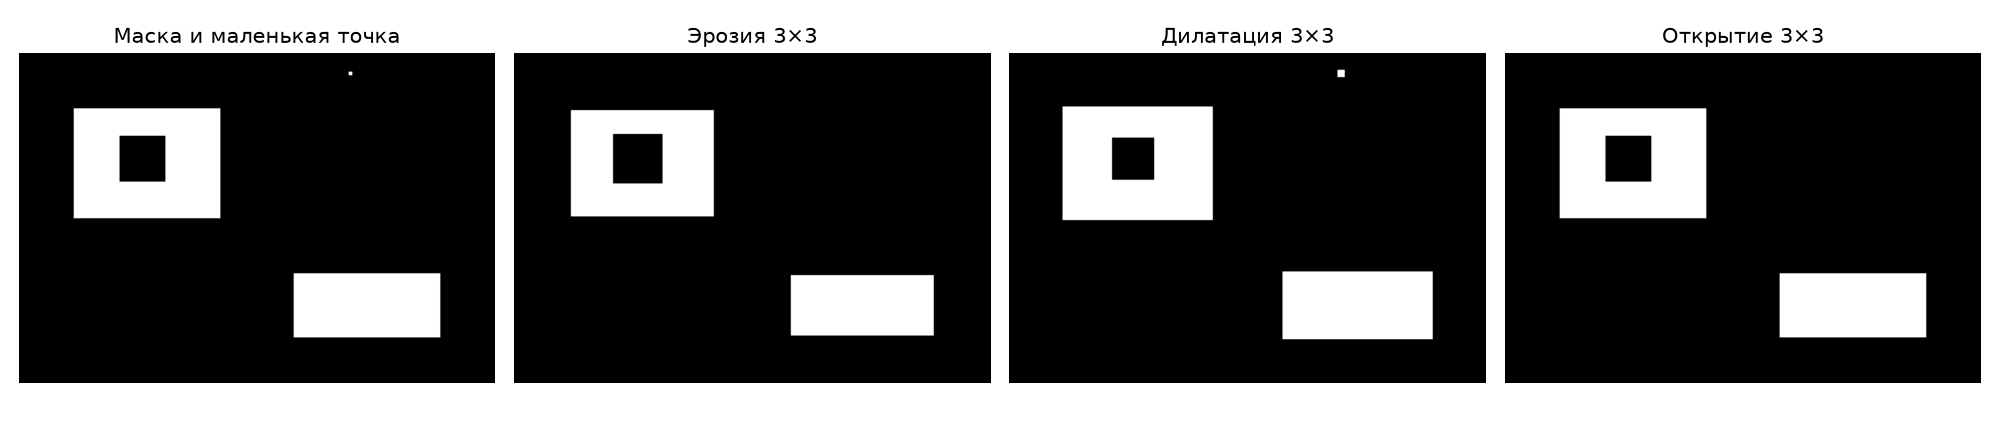


### 6. Маска, граница и контур — не одно и то же

Для маски 0/1 вычтем её эрозию из самой маски. Эрозия не добавляет единиц, поэтому здесь разность не станет отрицательной. Получится внутреннее кольцо пикселей у границы. Это простое выделение границы, **не упорядоченный контур** в виде списка координат.


In [ ]:
inner_border = binary - eroded
plt.imshow(inner_border, cmap='gray', vmin=0, vmax=1)
plt.title('Внутренняя граница маски')
plt.show()


Контур в библиотеке — последовательность координат вдоль границы. У объекта с дыркой могут быть внешняя граница и внутренняя. Поэтому число контуров не всегда равно числу предметов. Связные белые области — ещё одно понятие: два предмета, соприкоснувшись в маске, могут стать одной областью.

OpenCV предлагает `findContours`: режим поиска определяет, нужны только внешние границы или ещё вложенные; метод аппроксимации — сколько точек хранить. Подробный вызов оставим дополнительным: сегодня важнее не смешать край, заполненную маску и геометрическое описание. Для следующего измерения возьмём заранее заданные области, поэтому автоматическое распознавание и поиск контуров нам не понадобятся.


### 7. Измерим ширину: сначала пиксели

На учебной картинке сверху лежит эталон, снизу предмет. Они лежат в одной плоскости, камера смотрит прямо; это заданные условия синтетического опыта. `plt.imread` читает серый PNG в диапазоне 0…1. Создадим маску условием `> 0.5` — порог теперь в этой шкале, а не 128.


### От маски к объектам: ещё одна договорённость

Две белые клетки, соприкасающиеся только углами, при связности 4 относятся к разным компонентам, а при связности 8 — к одной. Значит, число объектов не содержится в белых пикселях «само по себе»: нужны правило связности и определение того, что считаем предметом.

Контур хранит последовательность точек границы, связная компонента — целую область. Отверстие внутри предмета может дать дополнительный контур, не новый предмет. В следующем блоке это различие понадобится для поиска объектов; сейчас на учебном изображении **вручную известны две области интереса**. Мы измеряем предмет, но не объявляем ручное разделение автоматическим детектором.

In [ ]:
measurement_image = plt.imread(DATA_DIR / 'edges' / 'measure.png')
measurement_mask = measurement_image > 0.5
plt.imshow(measurement_mask, cmap='gray', vmin=0, vmax=1)
plt.title('Эталон сверху, предмет снизу')
plt.show()


Разделим верхнюю и нижнюю части срезами. Это **заданные вручную области интереса**, а не автоматическое обнаружение предметов. `[:100, :]` берёт первые 100 строк и все столбцы, `[100:, :]` — остальные строки. В каждой области ровно один белый прямоугольник.


In [ ]:
reference_mask = measurement_mask[:100, :]
object_mask = measurement_mask[100:, :]
print(reference_mask.shape, object_mask.shape)


`np.where(mask)` возвращает координаты элементов True: сначала массив номеров строк, потом столбцов. Распакуем их в две переменные. Для ширины нужны крайние **столбцы**, поэтому берём минимум и максимум x. Добавляем 1: столбцы 20…119 включительно занимают 100 пикселей, а не 99. Для пустой маски минимум не определён — в общем случае надо сначала проверить, что объект найден.


In [ ]:
reference_y, reference_x = np.where(reference_mask)
print(reference_x.min(), reference_x.max())
reference_width_px = reference_x.max() - reference_x.min() + 1
print('Эталон, пиксели:', reference_width_px)

object_y, object_x = np.where(object_mask)
object_width_px = object_x.max() - object_x.min() + 1
print('Предмет, пиксели:', object_width_px)


### 8. Переведём пиксели в миллиметры

По условию эталон шириной 50 мм занимает 100 пикселей. Деление миллиметров на пиксели даёт масштаб **мм/пиксель**. Ширину предмета в пикселях умножаем на этот масштаб. Это ширина ограничивающей рамки в наших условиях, не длина произвольно повёрнутого объекта.


In [ ]:
reference_width_mm = 50
mm_per_pixel = reference_width_mm / reference_width_px
object_width_mm = object_width_px * mm_per_pixel
print('Масштаб, мм/пиксель:', mm_per_pixel)
print('Ширина предмета, мм:', object_width_mm)


Учебный эталон для чтения без запуска: сверху 100 пикселей соответствуют 50 мм, снизу известная ширина предмета — 80 мм. На реальном снимке масштаб меняется с перспективой и расстоянием; эталон в другой плоскости уже не даёт нам тот же пересчёт.

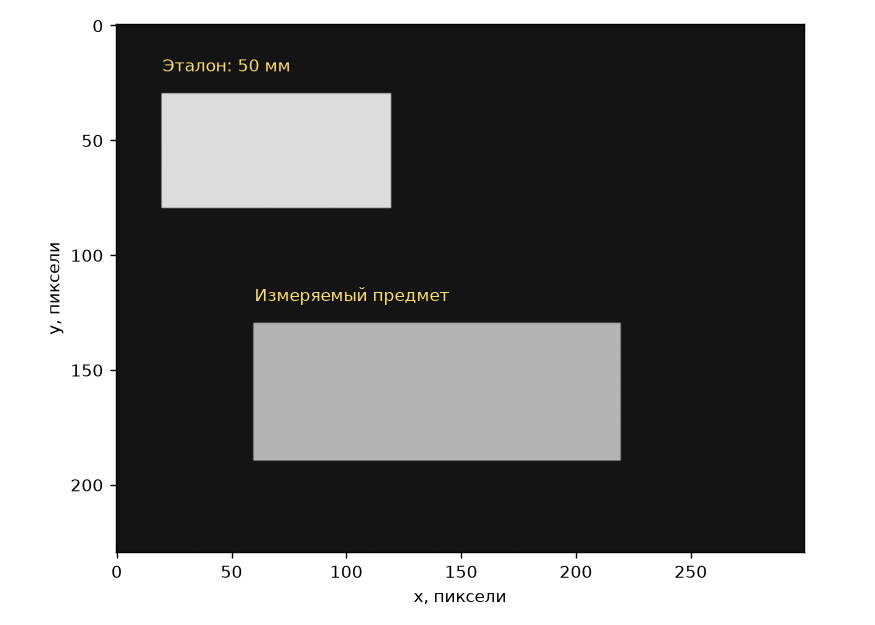


Абсолютная ошибка — модуль разности измерения и известной истинной величины: `abs(measured - true)`, в тех же миллиметрах. Относительная ошибка — абсолютная ошибка, делённая на истинную величину; умножим на 100, чтобы получить проценты. Истинное значение в нашем примере известно из генерации изображения. У произвольной фотографии его нужно установить независимым измерением, а не просто объявить результат алгоритма истиной.

В исходной маске мы получили ровно 80 мм: картинка специально идеальная. Теперь **вручную моделируем ошибку выделения границ**: пусть найденная ширина оказалась 154 пикселя вместо 160. Это контролируемый опыт, а не утверждение, что алгоритм на фотографии всегда ошибается именно так.


### ✏️ Ваш ход — посчитать ошибку измерения

Для пробной ширины 154 пикселя вычислите `trial_width_mm`, `absolute_error_mm`, `relative_error_percent`. Используйте масштаб эталона и истинную ширину 80 мм. В выводе назовите две причины ошибки на реальном снимке и объясните, какую из них наш идеальный опыт не моделирует.


In [ ]:
# ✏️ ваш код здесь


In [ ]:
check('04.2.3', trial_width_mm, absolute_error_mm, relative_error_percent)


**Мой вывод:** замените эту строку своим объяснением результата. Назовите конкретное число, поле или участок изображения, на который опираетесь.


### Дополнительно: как это выглядит в OpenCV

У `cv2.erode` и `cv2.dilate` тот же смысл, который мы вычислили минимумом и максимумом. `np.ones((3, 3), dtype=np.uint8)` создаёт полное окно из единиц. Чтобы сравнение с нашей функцией было честным, явно задаём одинаковую рамку: `borderType=cv2.BORDER_CONSTANT, borderValue=0`. Без одинаковых условий результаты у края могут различаться.

```python
import cv2
kernel = np.ones((3, 3), dtype=np.uint8)
cv_eroded = cv2.erode(binary, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)
cv_dilated = cv2.dilate(binary, kernel, borderType=cv2.BORDER_CONSTANT, borderValue=0)
```

Автоматический порог Оцу выбирает глобальный порог по гистограмме; адаптивная бинаризация определяет порог локально. Это полезные инструменты при подходящих условиях, а не гарантия выделить нужный объект. Сейчас достаточно понимать, какую проблему они пытаются решить. [Документация по морфологии](https://docs.opencv.org/4.x/d9/d61/tutorial_py_morphological_ops.html).

### Что сохранить и как начать ЛР2

Сохраните свои маски, результаты опытов и расчёт в этой тетради. Откройте `docs/ЛР2.md`: там результат блока 03–04 и критерии. Можно работать на предоставленных синтетических изображениях и NumPy; свой фотоаппарат, OpenCV и публикация на GitHub не обязательны. Одних готовых картинок из этой тетради для сдачи недостаточно — нужен ваш выполненный опыт, параметры, расчёты и объяснение.

В следующем блоке будем искать устойчивые локальные детали изображения. Сегодняшний вывод пригодится: большое количество откликов ещё не означает, что мы нашли то, что нужно.
